In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset berita hoaks vs valid
df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
print('Distribusi label:')
print(df['label'].value_counts())
df.head()


Dimensi data: (1498, 2)
Distribusi label:
label
1    749
0    749
Name: count, dtype: int64


,teks_bersih,label
0,presiden prabowo minta maaf ikut bop akan kemb...,1
1,video presiden prabowo akan membagikan bantuan...,1
2,pemerintah kota tangerang selatan akan legalka...,1
3,tautan rekrutmen cpns kementerian imigrasi,1
4,ramuan rebusan jahe kunyit kencur dan serai be...,1


In [2]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenisasi dan padding sekuens teks
X_raw = df['teks_bersih'].astype(str).tolist()
y = df['label'].to_numpy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

max_words = 5000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_raw)

X_train = pad_sequences(tokenizer.texts_to_sequences(X_train_raw), maxlen=max_len, padding='post')
X_test = pad_sequences(tokenizer.texts_to_sequences(X_test_raw), maxlen=max_len, padding='post')

print('Dimensi data latih teks:', X_train.shape)
print('Dimensi data uji teks  :', X_test.shape)


Dimensi data latih teks: (1198, 100)
Dimensi data uji teks  : (300, 100)


In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

tf.random.set_seed(42)

# Model 1D-CNN (TextCNN) untuk klasifikasi berita biner
model_textcnn = Sequential([
    Embedding(input_dim=max_words, output_dim=64),
    Conv1D(filters=128, kernel_size=5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_textcnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model_textcnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Pelatihan model TextCNN
history_pbl = model_textcnn.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/15


 1/30 ━━━━━━━━━━━━━━━━━━━━ 1:05 2s/step - accuracy: 0.6250 - loss: 0.6880

 8/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6328 - loss: 0.6833 

15/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6542 - loss: 0.6808

22/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7003 - loss: 0.6724

29/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7231 - loss: 0.6649

... (96 outputs left out)

15/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 4.3806e-04

22/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 3.7624e-04

27/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 3.5124e-04

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 3.5736e-04 - val_accuracy: 0.9250 - val_loss: 0.2651


In [5]:
from sklearn.metrics import classification_report, confusion_matrix

# Evaluasi performa model data uji
test_loss, test_acc = model_textcnn.evaluate(X_test, y_test, verbose=0)
print(f'Loss Data Uji TextCNN    : {test_loss:.4f}')
print(f'Akurasi Data Uji TextCNN : {test_acc * 100:.2f}%')
print()

y_pred_prob = model_textcnn.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print('Classification Report TextCNN:')
print(classification_report(y_test, y_pred, target_names=['Valid', 'Hoaks']))


Loss Data Uji TextCNN    : 0.4526
Akurasi Data Uji TextCNN : 87.67%



 1/10 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step 

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


Classification Report TextCNN:
              precision    recall  f1-score   support

       Valid       0.89      0.86      0.87       150
       Hoaks       0.86      0.89      0.88       150

    accuracy                           0.88       300
   macro avg       0.88      0.88      0.88       300
weighted avg       0.88      0.88      0.88       300



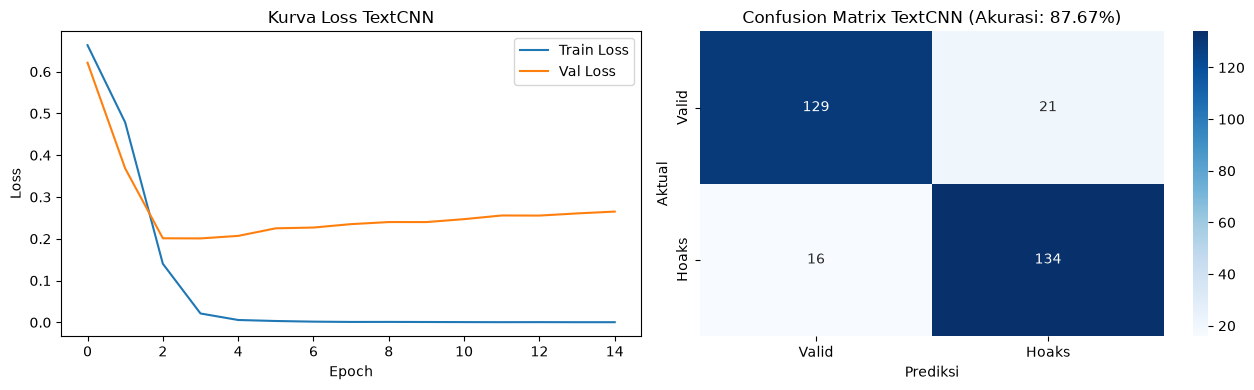

In [6]:
# Visualisasi kurva pelatihan dan confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_pbl.history['loss'], label='Train Loss')
axes[0].plot(history_pbl.history['val_loss'], label='Val Loss')
axes[0].set_title('Kurva Loss TextCNN')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Valid', 'Hoaks'], yticklabels=['Valid', 'Hoaks'])
axes[1].set_title(f'Confusion Matrix TextCNN (Akurasi: {test_acc*100:.2f}%)')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()
